# [15.5] VLM LoRA (solutions)

> **Colab: [exercises](https://colab.research.google.com/github/shinobiultra/ARENA_3.0_Extended/blob/main/chapter15_peft_misalignment/exercises/part5_vlm_lora/15.5_VLM_LoRA_exercises.ipynb) |
> [solutions](https://colab.research.google.com/github/shinobiultra/ARENA_3.0_Extended/blob/main/chapter15_peft_misalignment/exercises/part5_vlm_lora/15.5_VLM_LoRA_solutions.ipynb)**

This section is part of the ARENA extension. The solutions notebook is saved with all of its outputs, so you can use it as a reference for what every cell should produce.

You can collapse each section so only the headers are visible, by clicking the arrow symbol on the left hand side of the markdown header cells.

<img src="https://raw.githubusercontent.com/info-arena/ARENA_img/main/misc/headers/header-15-3.png" width="350">

# Introduction

The picture contains a red object on the left and a blue object on the right. Ask **“What color is the left object?”** and the model says **blue**. Now ask the same question with a different picture. Does the adapter fix the image pathway, or does it simply change what the language decoder means by the token “red”?

By the end of this notebook, you will have shown that **two exact rank-1 adapters can repair the same image-question answers while differing in language preservation**: a projector update corrects a known camera channel swap, while a language-module update also reverses ordinary color words. You will generate actual RGB scenes, implement visual-token attention and token logits, then compare object/background patching, modality ablations and rank/norm controls beside the answer accuracy.

This is a transparent, untrained **one-answer-token VLM fixture**, not a regression dataset renamed as a VLM. Pixels become patch tokens; a location question selects a visual region through attention; a language matrix and unembedding produce the answer token. Every matrix is small enough to inspect. The exact adapters are constructed, not fitted. Their performance is an analytic demonstration, not empirical model adaptation.

Section 12.3 connects SigLIP patch features through a trainable projector into GPT-2. We preserve that vision → projector → language decomposition but replace its pretrained encoders and multi-layer language model with explicit RGB means and a one-step decoder. The code here does **not** run the trained 12.3 checkpoint, nor does it establish results for a real VLM. The source-grounded bridge at the end states which tensors and controls transfer.

Prerequisites: 12.1 for modality controls, 12.3 for visual-token assembly and patching, and 15.1 for LoRA. All default examples run on CPU in float64 without a download or optimizer.

Before viewing the signature figure, predict: if projector and language adapters both reach perfect VQA, will both pass a language-only color-identity check? State the mechanism rather than treating VQA accuracy as a complete grounding metric.

## Content & Learning Objectives

### 1️⃣ Images and adapters

Render the two-object scenes, extract spatial patches and construct rank-1 updates at two different sites.

> ##### Learning Objectives
>
> - Keep pixel location, patch order and channel order explicit.
> - Implement LoRA factors and projector adaptation without hiding the forward path.
> - Distinguish a constructed calibration adapter from trained adaptation.

### 2️⃣ Question-conditioned decoding

Build attention from a location question to visual tokens and turn the pooled token into a red/blue answer.

> ##### Learning Objectives
>
> - Implement stable query/key attention and one-token language decoding.
> - Measure exact answer accuracy and signed target-token margins.
> - Expose text-only, image-only and shuffled-image conditions.

### 3️⃣ Grounding interventions

Patch target-object, other-object and background visual tokens from a clean scene into a counterfactual scene.

> ##### Learning Objectives
>
> - Implement batch-specific token replacement without mutating the source.
> - Normalize patch effects by the clean/counterfactual margin gap and handle undefined cases.
> - Separate causal information use from answer correctness.

### 4️⃣ Compare and transfer

Compare adaptation sites, parameter counts, spectra and language preservation, then change the kind of camera shift.

> ##### Learning Objectives
>
> - Use same-rank/norm random controls and an unshifted-camera reference.
> - Predict when a learned or constructed adapter should fail under a changed condition.

### ☆ Bonus

Trace the hook sites for a pretrained 12.3 experiment without silently running or claiming that experiment.

## Setup code

In [1]:
import sys
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt

chapter = 'chapter15_peft_misalignment'
section = 'part5_vlm_lora'
root_dir = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / chapter).is_dir())
exercises_dir = root_dir / chapter / 'exercises'
if str(exercises_dir) not in sys.path:
    sys.path.insert(0, str(exercises_dir))
import part5_vlm_lora.tests as tests
import part5_vlm_lora.utils as utils
MAIN = __name__ == '__main__'
np.set_printoptions(precision=4, suppress=True)

# 1️⃣ Images and adapters

> ##### Learning Objectives
>
> - Keep pixel location, patch order and channel order explicit.
> - Implement LoRA factors and projector adaptation without hiding the forward path.
> - Distinguish a constructed calibration adapter from trained adaptation.

## A visible task before a hidden state

An image is an `(8,8,3)` RGB array. The top-left 4×4 patch is one object; the top-right patch is another; the bottom patches are green background. Colors are literal red `[1,0,0]` and blue `[0,0,1]`. A question is either “left” or “right”, represented by a two-dimensional one-hot query. The answer vocabulary is exactly `[red, blue]`, in that order. This vocabulary order also determines ties: NumPy `argmax` chooses red on equal logits.

We will enumerate all four object-color combinations, both questions and four background intensities. That makes 32 image-question examples, balanced by answer, including cases where the same image has different correct answers for different questions. Background intensity is a controlled nuisance, not a new label. All examples are public analytic practice; there is no TRAIN/DEV/TEST split and no fitted model in this lesson.

### Exercise - implement `render_scene`

> ```yaml
> Difficulty: 🔴🔴⚪⚪⚪
> Importance: 🔵🔵🔵🔵⚪
> 
> You should spend up to 10-15 minutes on this exercise.
> ```

Return one float64 RGB image of shape `(8,8,3)`. Color id 0 means red and 1 means blue. Fill the top-left and top-right 4×4 blocks with their object colors and both bottom blocks with green intensity `background`.

In [2]:
def render_scene(left_color, right_color, background):
    palette = np.array([[1., 0., 0.], [0., 0., 1.]])
    image = np.zeros((8, 8, 3), dtype=np.float64)
    image[:4, :4] = palette[left_color]
    image[:4, 4:] = palette[right_color]
    image[4:, :, 1] = background
    return image

tests.test_render_scene(render_scene)

All tests in `test_render_scene` passed!


<details><summary>Hint</summary>

Array slices broadcast a three-channel color across the selected region.

</details>

<details><summary>Expected output</summary>

For `(0,1,0.3)`, top-left is `[1,0,0]`, top-right `[0,0,1]` and bottom `[0,0.3,0]`. The immediate check prints `All tests in test_render_scene passed!`, with the test name in backticks.

</details>

<details><summary>Help - connect the computation to the task</summary>

Return one float64 RGB image of shape `(8,8,3)`. Color id 0 means red and 1 means blue. Fill the top-left and top-right 4×4 blocks with their object colors and both bottom blocks with green intensity `background`. Trace which image region and which question this operation can depend on; the later controls will change one of those dependencies.

</details>

### Exercise - implement `patchify`

> ```yaml
> Difficulty: 🔴🔴⚪⚪⚪
> Importance: 🔵🔵🔵🔵⚪
> 
> You should spend up to 10-15 minutes on this exercise.
> ```

Convert image batches `(batch,8,8,3)` into patches `(batch,4,4,4,3)`, ordered top-left, top-right, bottom-left, bottom-right. Preserve spatial pixel order within every patch.

In [3]:
def patchify(images):
    return np.stack([images[:, :4, :4], images[:, :4, 4:], images[:, 4:, :4], images[:, 4:, 4:]], axis=1)

tests.test_patchify(patchify)

All tests in `test_patchify` passed!


<details><summary>Hint</summary>

A single reshape without a suitable transpose mixes spatial axes; explicit slices make the order unambiguous.

</details>

<details><summary>Expected output</summary>

The integer-ramp test checks every pixel against independently sliced quadrants, not only the output shape. The immediate check prints `All tests in test_patchify passed!`, with the test name in backticks.

</details>

<details><summary>Help - connect the computation to the task</summary>

Convert image batches `(batch,8,8,3)` into patches `(batch,4,4,4,3)`, ordered top-left, top-right, bottom-left, bottom-right. Preserve spatial pixel order within every patch. Trace which image region and which question this operation can depend on; the later controls will change one of those dependencies.

</details>

## A tiny vision encoder with a known domain shift

Our fixed vision encoder averages each patch's pixels, producing `(batch,4,3)` features. It discards texture but retains mean color and location through patch order. A new camera swaps the red and blue channels, so its output ordering is `[blue, green, red]`. The images shown to you still use ordinary RGB; `camera_swap=True` models what the encoder receives after the channel-order error. We know the shift exactly, so there is no mystery about the correct calibration.

This is a deliberately easy visual representation. A pretrained SigLIP encoder is neither a mean-color extractor nor a channel permutation, but its cached patch-feature tensor plays the same architectural role.

### Exercise - implement `vision_features`

> ```yaml
> Difficulty: 🔴🔴⚪⚪⚪
> Importance: 🔵🔵🔵🔵⚪
> 
> You should spend up to 10-15 minutes on this exercise.
> ```

Average over the two within-patch pixel axes and optionally swap red/blue feature channels. Do not average over the batch, patch or channel axes.

In [4]:
def vision_features(patches, camera_swap):
    features = patches.mean(axis=(2, 3))
    return features[..., [2, 1, 0]] if camera_swap else features

tests.test_vision_features(vision_features)

All tests in `test_vision_features` passed!


<details><summary>Hint</summary>

The output must retain one three-channel vector per spatial patch.

</details>

<details><summary>Expected output</summary>

A red patch encodes `[1,0,0]` normally and `[0,0,1]` with the camera swap. The immediate check prints `All tests in test_vision_features passed!`, with the test name in backticks.

</details>

<details><summary>Help - connect the computation to the task</summary>

Average over the two within-patch pixel axes and optionally swap red/blue feature channels. Do not average over the batch, patch or channel axes. Trace which image region and which question this operation can depend on; the later controls will change one of those dependencies.

</details>

Images / features / queries: (32, 8, 8, 3) (32, 4, 3) (32, 2)
Answer counts: [16 16]


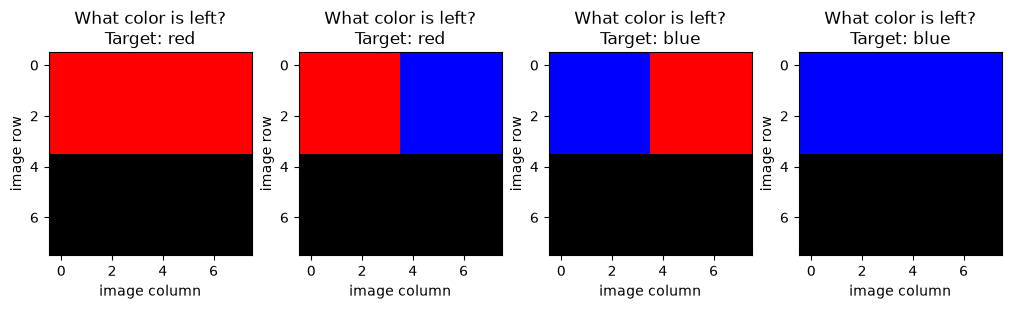

In [5]:
manifest = [(left, right, background, question) for background in [0., .25, .5, .75] for left in [0, 1] for right in [0, 1] for question in [0, 1]]
images = np.stack([render_scene(left, right, background) for left, right, background, question in manifest])
question_ids = np.array([question for left, right, background, question in manifest])
labels = np.array([left if question == 0 else right for left, right, background, question in manifest])
answer_names = np.array(['red', 'blue'])
queries = np.eye(2)[question_ids]
features = vision_features(patchify(images), camera_swap=True)
normal_features = vision_features(patchify(images), camera_swap=False)
print('Images / features / queries:', images.shape, features.shape, queries.shape)
print('Answer counts:', np.bincount(labels))
utils.show_scenes(images, question_ids, answer_names[labels])
plt.show()

<details><summary>Expected output and interpretation</summary>

<pre>Images / features / queries: (32, 8, 8, 3) (32, 4, 3) (32, 2)
Answer counts: [16 16]</pre>

The four displayed examples ask about the left object and show all color combinations. Every image also appears with the right-object question in the complete manifest. A model that ignores location can look partly successful when both objects have the same color; the image-only control will expose this.

</details>

## Two rank-one correction sites

The projector $P\in\mathbb R^{4\times3}$ maps red-channel evidence to hidden coordinate 0, blue to hidden coordinate 1, green to coordinate 2, and leaves coordinate 3 unused. The frozen language matrix $L=I_4$ maps the attended hidden state to a decoder state. Unembedding $U\in\mathbb R^{2\times4}$ reads hidden coordinates 0 and 1 as red and blue logits.

With swapped camera features, there are two exact fixes. A projector update swaps the two relevant input-channel effects **before** they enter language space. A language update swaps hidden coordinates 0 and 1 **after** pooling. Both updates are rank 1: swapping two coordinates is identity plus an outer product along their contrast. The important difference is what else passes through the modified site. Ordinary text states also pass through $L$, but never through the visual projector.

### Exercise - implement `lora_update`

> ```yaml
> Difficulty: 🔴🔴⚪⚪⚪
> Importance: 🔵🔵🔵🔵⚪
> 
> You should spend up to 10-15 minutes on this exercise.
> ```

Return `(alpha/r) * B @ A` from factors `A` of shape `(r,din)` and `B` of shape `(dout,r)`. Use the same output-by-input convention at both adaptation sites.

In [6]:
def lora_update(A, B, alpha):
    return (alpha / A.shape[0]) * (B @ A)

tests.test_lora_update(lora_update)

All tests in `test_lora_update` passed!


<details><summary>Hint</summary>

A rank-one contrast is enough to exchange two coordinates relative to identity.

</details>

<details><summary>Expected output</summary>

The rectangular fixture with rank 1 and alpha 0.5 checks values and orientation; rank 2 checks the scaling denominator. The immediate check prints `All tests in test_lora_update passed!`, with the test name in backticks.

</details>

<details><summary>Help - connect the computation to the task</summary>

Return `(alpha/r) * B @ A` from factors `A` of shape `(r,din)` and `B` of shape `(dout,r)`. Use the same output-by-input convention at both adaptation sites. Trace which image region and which question this operation can depend on; the later controls will change one of those dependencies.

</details>

### Exercise - implement `project_tokens`

> ```yaml
> Difficulty: 🔴🔴⚪⚪⚪
> Importance: 🔵🔵🔵🔵⚪
> 
> You should spend up to 10-15 minutes on this exercise.
> ```

Apply a frozen projector plus its adapter to every patch feature, returning `(batch,patch,hidden)`. `projector` and `delta` both have shape `(hidden,3)`.

In [7]:
def project_tokens(features, projector, delta):
    return features @ (projector + delta).T

tests.test_project_tokens(project_tokens)

All tests in `test_project_tokens` passed!


<details><summary>Hint</summary>

Do not add the adapter after projection: it maps vision features into hidden space.

</details>

<details><summary>Expected output</summary>

The two-token test returns `[[[4,-1],[1,-1]]]` for the adapted projector. The immediate check prints `All tests in test_project_tokens passed!`, with the test name in backticks.

</details>

<details><summary>Help - connect the computation to the task</summary>

Apply a frozen projector plus its adapter to every patch feature, returning `(batch,patch,hidden)`. `projector` and `delta` both have shape `(hidden,3)`. Trace which image region and which question this operation can depend on; the later controls will change one of those dependencies.

</details>

In [8]:
projector = np.array([[1., 0., 0.], [0., 0., 1.], [0., 1., 0.], [0., 0., 0.]])
language = np.eye(4)
unembed = np.eye(4)[:2]
projector_A = np.array([[1., 0., -1.]])
projector_B = np.array([[-1.], [1.], [0.], [0.]])
language_A = np.array([[1., -1., 0., 0.]])
language_B = np.array([[-1.], [1.], [0.], [0.]])
delta_projector = lora_update(projector_A, projector_B, 1.)
delta_language = lora_update(language_A, language_B, 1.)
print('Projector correction:')
print(delta_projector)
print('Language correction:')
print(delta_language)
print('Update Frobenius norms:', np.linalg.norm(delta_projector), np.linalg.norm(delta_language))

Projector correction:
[[-1.  0.  1.]
 [ 1.  0. -1.]
 [ 0.  0.  0.]
 [ 0.  0.  0.]]
Language correction:
[[-1.  1.  0.  0.]
 [ 1. -1.  0.  0.]
 [ 0.  0.  0.  0.]
 [ 0.  0.  0.  0.]]
Update Frobenius norms: 2.0 2.0


<details><summary>Expected output</summary>

Both update norms are 2. The projector update has nonzero rows `[-1,0,1]` and `[1,0,-1]`; the language update has nonzero rows `[-1,1,0,0]` and `[1,-1,0,0]`. Remaining rows are zero. Each update has one nonzero singular value, 2.

</details>

## Summary of 1️⃣

You now have real images, an explicit patch order, question/answer metadata and two inspectable low-rank corrections. Equal rank and norm do not imply equal effects on text, because adaptation sites have different traffic.

# 2️⃣ Question-conditioned decoding

> ##### Learning Objectives
>
> - Implement stable query/key attention and one-token language decoding.
> - Measure exact answer accuracy and signed target-token margins.
> - Expose text-only, image-only and shuffled-image conditions.

## A location question must select a region

Patch position keys are $k_0=(1,0)$ for the left object, $k_1=(0,1)$ for the right object, and zero for each background patch. The question query is $q=(1,0)$ or $(0,1)$. Define

$$a_{bp}=\operatorname{softmax}_p(\beta q_b^\top k_p),\qquad h_b=t_b+\sum_p a_{bp}z_{bp},\qquad \ell_b=ULh_b.$$

Here $z$ are projected visual tokens and $t$ is a text residual. VQA uses zero text residual: the location question controls attention, but carries no color clue. Language-only color identity probes later use a text state and zero visual tokens. With $\beta=6$, attention is strong but not hard: the selected object gets approximately 0.9926 and each other patch approximately 0.00246. This lets you see small distractor effects in causal patching.

Subtracting the row maximum before exponentiation preserves softmax while preventing overflow. Dividing by a global sum would mix examples and make the answer to one image depend on other images in the batch.

### Exercise - implement `query_attention`

> ```yaml
> Difficulty: 🔴🔴⚪⚪⚪
> Importance: 🔵🔵🔵🔵⚪
> 
> You should spend up to 10-15 minutes on this exercise.
> ```

Return `(batch,patch)` attention from `(batch,2)` queries and `(patch,2)` keys, scaled by `strength`. Normalize across patches separately for each example, stably.

In [9]:
def query_attention(queries, keys, strength):
    scores = strength * (queries @ keys.T)
    scores = scores - scores.max(axis=1, keepdims=True)
    weights = np.exp(scores)
    return weights / weights.sum(axis=1, keepdims=True)

tests.test_query_attention(query_attention)

All tests in `test_query_attention` passed!


<details><summary>Hint</summary>

The test uses strength log(2), so the exact weights are simple fractions.

</details>

<details><summary>Expected output</summary>

For three keys left/right/zero and left/right queries, weights are `[0.5,0.25,0.25]` and `[0.25,0.5,0.25]`. Strength 1000 must stay finite. The immediate check prints `All tests in test_query_attention passed!`, with the test name in backticks.

</details>

<details><summary>Help - connect the computation to the task</summary>

Return `(batch,patch)` attention from `(batch,2)` queries and `(patch,2)` keys, scaled by `strength`. Normalize across patches separately for each example, stably. Trace which image region and which question this operation can depend on; the later controls will change one of those dependencies.

</details>

### Exercise - implement `decode_answers`

> ```yaml
> Difficulty: 🔴🔴⚪⚪⚪
> Importance: 🔵🔵🔵🔵⚪
> 
> You should spend up to 10-15 minutes on this exercise.
> ```

Pool visual tokens with per-example attention, add a text residual, apply the language matrix and unembedding. Return `(batch,2)` red/blue logits in this lesson; tests also check a three-token vocabulary.

In [10]:
def decode_answers(tokens, attention, text_states, language_weight, unembed):
    pooled = np.sum(tokens * attention[..., None], axis=1)
    hidden = pooled + text_states
    return (hidden @ language_weight.T) @ unembed.T

tests.test_decode_answers(decode_answers)

All tests in `test_decode_answers` passed!


<details><summary>Hint</summary>

The text residual passes through the language matrix too; forgetting that would hide its side effect.

</details>

<details><summary>Expected output</summary>

The independent loop oracle adds each weighted token to text, then applies `unembed @ (language @ h)` example by example. The immediate check prints `All tests in test_decode_answers passed!`, with the test name in backticks.

</details>

<details><summary>Help - connect the computation to the task</summary>

Pool visual tokens with per-example attention, add a text residual, apply the language matrix and unembedding. Return `(batch,2)` red/blue logits in this lesson; tests also check a three-token vocabulary. Trace which image region and which question this operation can depend on; the later controls will change one of those dependencies.

</details>

## Score the answer, then retain the margin

Accuracy counts exact token matches over all 32 examples. The answer margin is target-token logit minus the other-token logit. Positive means the correct token is preferred; zero is a tie resolved toward red by the frozen vocabulary order. Do not substitute probability of red for probability of the target: blue examples need the opposite comparison.

Margins will also measure causal patching. They retain signed changes that a saturated 0/1 accuracy can hide. We use a two-token margin here because the full vocabulary is exactly two tokens; for a real decoder you must state whether the competitor is a named counterfactual token, the maximum non-target token, or a full-distribution metric.

### Exercise - implement `accuracy`

> ```yaml
> Difficulty: 🔴🔴⚪⚪⚪
> Importance: 🔵🔵🔵🔵⚪
> 
> You should spend up to 10-15 minutes on this exercise.
> ```

Return exact top-1 answer accuracy from logits and integer target labels. Preserve the frozen first-index tie convention of NumPy argmax.

In [11]:
def accuracy(logits, labels):
    return float(np.mean(np.argmax(logits, axis=-1) == labels))

tests.test_accuracy(accuracy)

All tests in `test_accuracy` passed!


<details><summary>Hint</summary>

Each image-question pair contributes one indicator.

</details>

<details><summary>Expected output</summary>

The test with one deliberately blue-target tie gives accuracy 0.75. The immediate check prints `All tests in test_accuracy passed!`, with the test name in backticks.

</details>

<details><summary>Help - connect the computation to the task</summary>

Return exact top-1 answer accuracy from logits and integer target labels. Preserve the frozen first-index tie convention of NumPy argmax. Trace which image region and which question this operation can depend on; the later controls will change one of those dependencies.

</details>

### Exercise - implement `answer_margin`

> ```yaml
> Difficulty: 🔴🔴⚪⚪⚪
> Importance: 🔵🔵🔵🔵⚪
> 
> You should spend up to 10-15 minutes on this exercise.
> ```

For two-token logits, return one signed target-minus-other margin per example. Labels are 0 for red and 1 for blue.

In [12]:
def answer_margin(logits, labels):
    rows = np.arange(len(labels))
    return logits[rows, labels] - logits[rows, 1 - labels]

tests.test_answer_margin(answer_margin)

All tests in `test_answer_margin` passed!


<details><summary>Hint</summary>

Use batch indexing twice; do not subtract a shared class from every target.

</details>

<details><summary>Expected output</summary>

Logits `[[4,1],[2,5],[-1,3]]`, labels `[0,1,0]` give `[3,3,-4]`. The immediate check prints `All tests in test_answer_margin passed!`, with the test name in backticks.

</details>

<details><summary>Help - connect the computation to the task</summary>

For two-token logits, return one signed target-minus-other margin per example. Labels are 0 for red and 1 for blue. Trace which image region and which question this operation can depend on; the later controls will change one of those dependencies.

</details>

In [13]:
keys = np.array([[1., 0.], [0., 1.], [0., 0.], [0., 0.]])
attention = query_attention(queries, keys, 6.)
text_states = np.zeros((len(labels), 4))
base_tokens = project_tokens(features, projector, np.zeros_like(projector))
projector_tokens = project_tokens(features, projector, delta_projector)
base_logits = decode_answers(base_tokens, attention, text_states, language, unembed)
projector_logits = decode_answers(projector_tokens, attention, text_states, language, unembed)
language_logits = decode_answers(base_tokens, attention, text_states, language + delta_language, unembed)
normal_tokens = project_tokens(normal_features, projector, np.zeros_like(projector))
normal_logits = decode_answers(normal_tokens, attention, text_states, language, unembed)
print('Attention for left query:', attention[0])
print('Unshifted reference accuracy:', accuracy(normal_logits, labels))
print('Shifted base / projector / language:', [accuracy(x, labels) for x in [base_logits, projector_logits, language_logits]])
print('Question / target / base / projector / language (first 8)')
for i in range(8):
    print(('left' if question_ids[i] == 0 else 'right'), answer_names[labels[i]], answer_names[base_logits[i].argmax()], answer_names[projector_logits[i].argmax()], answer_names[language_logits[i].argmax()])

Attention for left query: [0.9926 0.0025 0.0025 0.0025]
Unshifted reference accuracy: 1.0
Shifted base / projector / language: [0.0, 1.0, 1.0]
Question / target / base / projector / language (first 8)
left red blue red red
right red blue red red
left red blue red red
right blue red blue blue
left blue red blue blue
right red blue red red
left blue red blue blue
right blue red blue blue


<details><summary>Expected output</summary>

<pre>Attention for left query: [0.9926 0.0025 0.0025 0.0025]
Unshifted reference accuracy: 1.0
Shifted base / projector / language: [0.0, 1.0, 1.0]</pre>

Both adapters repair all shifted-camera answers. This result alone cannot tell you whether either adapter preserves language, whether the image is necessary, or whether the correct object supplies the evidence.

</details>

## Summary of 2️⃣

You have built an image-conditioned answer model, rather than fitting an unrelated regression head. A location query controls attention, visual evidence affects token logits, and both adaptation sites solve the calibration task. The missing question is what else those sites change.

# 3️⃣ Grounding interventions

> ##### Learning Objectives
>
> - Implement batch-specific token replacement without mutating the source.
> - Normalize patch effects by the clean/counterfactual margin gap and handle undefined cases.
> - Separate causal information use from answer correctness.

## Counterfactual pairs and local replacement

For every example, construct a counterfactual image by exchanging both objects' red/blue colors and inverting the background's green intensity. Keep the question and target label from the original image fixed. A correctly grounded model should now prefer the *opposite* answer; the original answer margin becomes negative. Patching a clean visual token into the counterfactual sequence asks whether that token is sufficient to recover the original answer.

Patch **one token per example**: the queried object, the other object, or a background patch. These conditions all replace the same number of tokens. Background values change too, so background patching is a nontrivial pixel intervention; our decoder ignores the green hidden coordinate by construction. At a pretrained model, a background region may carry useful scene information and need not be a null control.

The donor and receiver must be paired by example, not shuffled together. Never overwrite the clean donor or mutate the receiver in place: that can make later controls depend on execution order.

### Exercise - implement `replace_tokens`

> ```yaml
> Difficulty: 🔴🔴⚪⚪⚪
> Importance: 🔵🔵🔵🔵⚪
> 
> You should spend up to 10-15 minutes on this exercise.
> ```

Copy the receiver `(batch,patch,hidden)` array and replace one token per example from the paired donor at the supplied integer `indices` `(batch,)`. Return the new array and leave both inputs unchanged.

In [14]:
def replace_tokens(receiver, donor, indices):
    patched = receiver.copy()
    rows = np.arange(len(receiver))
    patched[rows, indices] = donor[rows, indices]
    return patched

tests.test_replace_tokens(replace_tokens)

All tests in `test_replace_tokens` passed!


<details><summary>Hint</summary>

Advanced indexing with row indices pairs each example with its own selected patch.

</details>

<details><summary>Expected output</summary>

The test patches token 0 only in example 0 and token 1 only in example 1, then verifies all other values and original receivers. The immediate check prints `All tests in test_replace_tokens passed!`, with the test name in backticks.

</details>

<details><summary>Help - connect the computation to the task</summary>

Copy the receiver `(batch,patch,hidden)` array and replace one token per example from the paired donor at the supplied integer `indices` `(batch,)`. Return the new array and leave both inputs unchanged. Trace which image region and which question this operation can depend on; the later controls will change one of those dependencies.

</details>

## Normalize a patch effect without hiding failure

Let $m_{clean}$ be the original-target margin on the clean image, $m_{corrupt}$ the same target's margin on the counterfactual image, and $m_{patch}$ the patched margin. Define

$$R=\frac{m_{patch}-m_{corrupt}}{m_{clean}-m_{corrupt}}.$$

Compute the ratio **per example**, then report its mean and the valid count. If the clean/corrupt gap is zero, return NaN: the pair has no measurable gap to recover. Do not turn it into zero or one. Do not clip: values above one or below zero can reveal interactions or competing evidence.

A crucial anomaly: a systematically wrong model can still have recovery near one. The ratio measures movement toward *that model's own clean outcome*, not toward truth. Always inspect accuracy and the signed clean/corrupt margins beside the normalized patch effect.

### Exercise - implement `margin_recovery`

> ```yaml
> Difficulty: 🔴🔴⚪⚪⚪
> Importance: 🔵🔵🔵🔵⚪
> 
> You should spend up to 10-15 minutes on this exercise.
> ```

Compute per-example normalized recovery. Return NaN when the denominator has absolute value at most `1e-12`; otherwise retain the signed ratio without clipping.

In [15]:
def margin_recovery(clean, corrupt, patched):
    denominator = clean - corrupt
    result = np.full_like(denominator, np.nan, dtype=np.float64)
    np.divide(patched - corrupt, denominator, out=result, where=np.abs(denominator) > 1e-12)
    return result

tests.test_margin_recovery(margin_recovery)

All tests in `test_margin_recovery` passed!


<details><summary>Hint</summary>

Use np.divide with a where mask so zero denominators are not evaluated.

</details>

<details><summary>Expected output</summary>

Clean `[3,4]`, corrupt `[-1,0]`, patched `[1,4]` gives `[0.5,1]`; equal clean/corrupt margins give NaN. The immediate check prints `All tests in test_margin_recovery passed!`, with the test name in backticks.

</details>

<details><summary>Help - connect the computation to the task</summary>

Compute per-example normalized recovery. Return NaN when the denominator has absolute value at most `1e-12`; otherwise retain the signed ratio without clipping. Trace which image region and which question this operation can depend on; the later controls will change one of those dependencies.

</details>

In [16]:
corrupt_images = np.stack([render_scene(1-left, 1-right, 1-background) for left, right, background, question in manifest])
corrupt_features = vision_features(patchify(corrupt_images), camera_swap=True)
corrupt_projector_tokens = project_tokens(corrupt_features, projector, delta_projector)
clean_margin = answer_margin(projector_logits, labels)
corrupt_margin = answer_margin(decode_answers(corrupt_projector_tokens, attention, text_states, language, unembed), labels)
region_indices = {'target object': question_ids, 'other object': 1-question_ids, 'background': np.full(len(labels), 2)}
for region, indices in region_indices.items():
    patched = replace_tokens(corrupt_projector_tokens, projector_tokens, indices)
    patched_margin = answer_margin(decode_answers(patched, attention, text_states, language, unembed), labels)
    recovery = margin_recovery(clean_margin, corrupt_margin, patched_margin)
    print(f'{region:14s} recovery={np.nanmean(recovery):.6f}; valid={np.isfinite(recovery).sum()}/{len(recovery)}')

target object  recovery=1.000006; valid=32/32
other object   recovery=-0.000006; valid=32/32
background     recovery=0.000000; valid=32/32


<details><summary>Expected output and interpretation</summary>

For the projector adapter, target-object mean recovery is approximately 1.000006, other-object recovery approximately -0.000006, and background recovery 0, with 32/32 valid pairs in each condition. The small negative distractor mean is real, not a failed test. When the two objects have opposite colors, the tiny non-target attention weight opposes the queried object; changing only that distractor can move the target margin away from the clean result. A clipped metric would hide this.

</details>

## Summary of 3️⃣

You can now locate the visual information that changes a token margin and recognize that normalized recovery is not an answer-quality metric. The next part puts grounding, correctness and language preservation beside each other so none can substitute for another.

# 4️⃣ Compare and transfer

> ##### Learning Objectives
>
> - Use same-rank/norm random controls and an unshifted-camera reference.
> - Predict when a learned or constructed adapter should fail under a changed condition.

## Random adapter and parameter-budget controls

The two exact updates each have rank 1 and Frobenius norm 2. For each site draw a random rank-one outer product and rescale to that same norm. This tests whether update *direction* matters, holding rank and total size fixed. The seed is fixed and public; it is not a multi-seed adaptation study. Do not select a favorable random seed after seeing outcomes.

The sites have different shapes. A LoRA adapter stores $r(d_{in}+d_{out})$ trainable scalar parameters; we omit bias and any learned alpha. The projector therefore has 7 parameters at rank 1 and the language matrix 8. Our comparison controls update rank/norm, not trainable parameter count or optimizer budget, and has no training at all.

Finally check retained spectral energy. In a constructed rank-one correction all update energy lies in one mode; that verifies the adapter construction. It does not show that one dimension explains arbitrary visual semantics.

### Exercise - implement `random_rank_one`

> ```yaml
> Difficulty: 🔴🔴⚪⚪⚪
> Importance: 🔵🔵🔵🔵⚪
> 
> You should spend up to 10-15 minutes on this exercise.
> ```

Draw a seeded rank-one outer product with the same shape and Frobenius norm as the target update. Return a zero matrix for a zero target.

In [17]:
def random_rank_one(update, seed):
    if np.linalg.norm(update) == 0:
        return np.zeros_like(update)
    rng = np.random.default_rng(seed)
    random = np.outer(rng.normal(size=update.shape[0]), rng.normal(size=update.shape[1]))
    return random * (np.linalg.norm(update) / np.linalg.norm(random))

tests.test_random_rank_one(random_rank_one)

All tests in `test_random_rank_one` passed!


<details><summary>Hint</summary>

The outer product is rank at most one; normalize the whole matrix, not individual rows.

</details>

<details><summary>Expected output</summary>

The fixture checks deterministic identity, rank 1 and norm 2 independently of the target direction. The immediate check prints `All tests in test_random_rank_one passed!`, with the test name in backticks.

</details>

<details><summary>Help - connect the computation to the task</summary>

Draw a seeded rank-one outer product with the same shape and Frobenius norm as the target update. Return a zero matrix for a zero target. Trace which image region and which question this operation can depend on; the later controls will change one of those dependencies.

</details>

### Exercise - implement `adapter_parameters`

> ```yaml
> Difficulty: 🔴🔴⚪⚪⚪
> Importance: 🔵🔵🔵🔵⚪
> 
> You should spend up to 10-15 minutes on this exercise.
> ```

Return the number of low-rank factor parameters for input width `din`, output width `dout` and rank `rank`, excluding frozen weights, bias and alpha.

In [18]:
def adapter_parameters(din, dout, rank):
    return rank * (din + dout)

tests.test_adapter_parameters(adapter_parameters)

All tests in `test_adapter_parameters` passed!


<details><summary>Hint</summary>

A has rank×din entries and B has dout×rank entries.

</details>

<details><summary>Expected output</summary>

Rank-one projector 3→4: 7 parameters; rank-one language 4→4: 8. The immediate check prints `All tests in test_adapter_parameters passed!`, with the test name in backticks.

</details>

<details><summary>Help - connect the computation to the task</summary>

Return the number of low-rank factor parameters for input width `din`, output width `dout` and rank `rank`, excluding frozen weights, bias and alpha. Trace which image region and which question this operation can depend on; the later controls will change one of those dependencies.

</details>

### Exercise - implement `retained_energy`

> ```yaml
> Difficulty: 🔴🔴⚪⚪⚪
> Importance: 🔵🔵🔵🔵⚪
> 
> You should spend up to 10-15 minutes on this exercise.
> ```

Return the fraction of squared singular-value energy in the leading `rank` modes. Return zero for a zero update.

In [19]:
def retained_energy(update, rank):
    squared = np.linalg.svd(update, compute_uv=False) ** 2
    return float(squared[:rank].sum() / squared.sum()) if squared.sum() > 0 else 0.0

tests.test_retained_energy(retained_energy)

All tests in `test_retained_energy` passed!


<details><summary>Hint</summary>

Use update energy rather than the rank of the frozen weight plus update.

</details>

<details><summary>Expected output</summary>

For diagonal `[3,4,0]`, rank-one retained energy is 0.64 and rank-two energy is 1. The immediate check prints `All tests in test_retained_energy passed!`, with the test name in backticks.

</details>

<details><summary>Help - connect the computation to the task</summary>

Return the fraction of squared singular-value energy in the leading `rank` modes. Return zero for a zero update. Trace which image region and which question this operation can depend on; the later controls will change one of those dependencies.

</details>

## Signature result: same VQA, different language cost

The language-only probe asks the decoder to name a color represented by a text state: red is $e_0$ and blue is $e_1$, repeated four times each in a fixed alternating order. Images are absent. It is an exact preservation check for this vocabulary, not a claim about natural-language fluency.

Next to it, compute VQA on the shifted-camera images. Then use the same clean/counterfactual pairs at every adapter site for the patch heatmap. The base model may patch perfectly while answering incorrectly, so the left panel is essential to reading the middle one. The final panel checks that exact and random controls really have matching singular spectra here: each is rank 1 with norm 2.

**Forecast:** which condition can have target-object recovery near one and VQA accuracy zero? What would happen if you judged that condition only by the patching heatmap?

base               VQA=0.0000; text identity=1.0000; valid patch pairs=32/32
projector LoRA     VQA=1.0000; text identity=1.0000; valid patch pairs=32/32
language LoRA      VQA=1.0000; text identity=0.0000; valid patch pairs=32/32
random projector   VQA=0.0000; text identity=1.0000; valid patch pairs=32/32
random language    VQA=0.0000; text identity=1.0000; valid patch pairs=32/32
Factor parameter counts: 7 8
Rank-one retained energies: 1.0 1.0


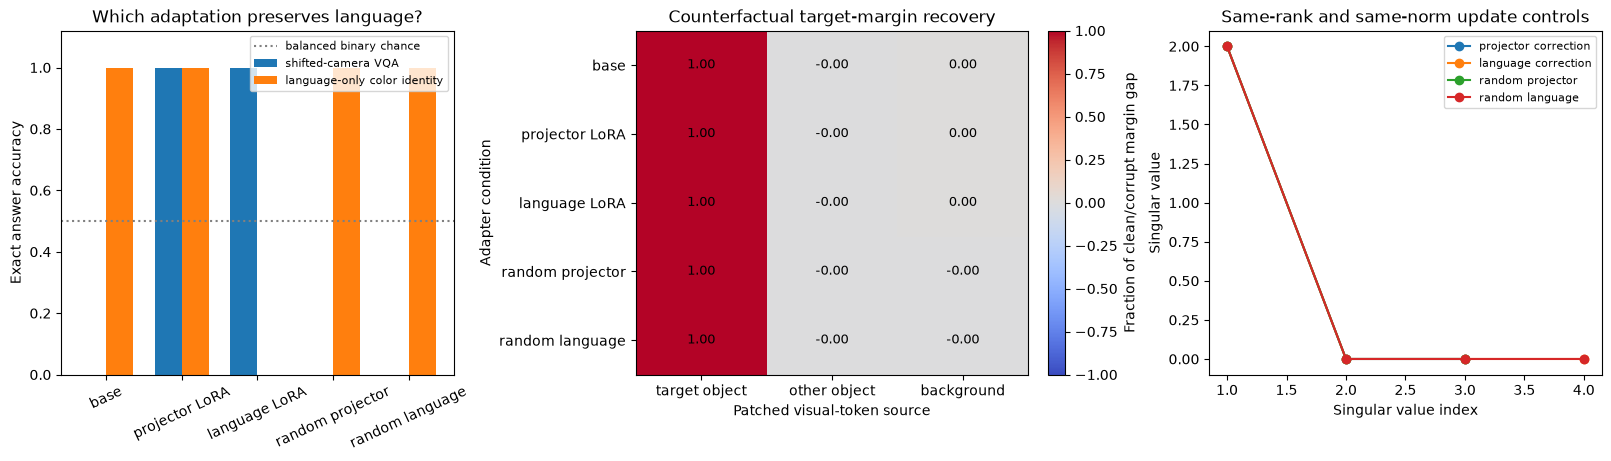

In [20]:
zero_P, zero_L = np.zeros_like(projector), np.zeros_like(language)
random_P = random_rank_one(delta_projector, 31)
random_L = random_rank_one(delta_language, 31)
conditions = {
    'base': (zero_P, zero_L),
    'projector LoRA': (delta_projector, zero_L),
    'language LoRA': (zero_P, delta_language),
    'random projector': (random_P, zero_L),
    'random language': (zero_P, random_L),
}
text_labels = np.tile([0, 1], 4)
identity_text = np.eye(4)[text_labels]
zero_visual = np.zeros((len(text_labels), 4, 4))
text_attention = np.full((len(text_labels), 4), .25)
vqa_scores, text_scores, recovery_rows = [], [], []
for name, (dP, dL) in conditions.items():
    clean_tokens = project_tokens(features, projector, dP)
    corrupt_tokens = project_tokens(corrupt_features, projector, dP)
    clean_logits = decode_answers(clean_tokens, attention, text_states, language + dL, unembed)
    corrupt_logits = decode_answers(corrupt_tokens, attention, text_states, language + dL, unembed)
    clean_m, corrupt_m = answer_margin(clean_logits, labels), answer_margin(corrupt_logits, labels)
    text_logits = decode_answers(zero_visual, text_attention, identity_text, language + dL, unembed)
    vqa_scores.append(accuracy(clean_logits, labels))
    text_scores.append(accuracy(text_logits, text_labels))
    row = []
    for region, indices in region_indices.items():
        patched_tokens = replace_tokens(corrupt_tokens, clean_tokens, indices)
        patched_logits = decode_answers(patched_tokens, attention, text_states, language + dL, unembed)
        values = margin_recovery(clean_m, corrupt_m, answer_margin(patched_logits, labels))
        row.append(np.nanmean(values))
    recovery_rows.append(row)
    print(f'{name:18s} VQA={vqa_scores[-1]:.4f}; text identity={text_scores[-1]:.4f}; valid patch pairs={np.isfinite(values).sum()}/32')
singular_values = {name: np.linalg.svd(d, compute_uv=False) for name, d in {'projector correction': delta_projector, 'language correction': delta_language, 'random projector': random_P, 'random language': random_L}.items()}
print('Factor parameter counts:', adapter_parameters(3, 4, 1), adapter_parameters(4, 4, 1))
print('Rank-one retained energies:', retained_energy(delta_projector, 1), retained_energy(delta_language, 1))
utils.signature(list(conditions), vqa_scores, text_scores, np.array(recovery_rows), singular_values)
plt.show()

<details><summary>Expected output and interpretation</summary>

Base VQA is 0 while text identity is 1. Both exact adapters achieve VQA 1, but projector LoRA preserves text identity 1 and language LoRA reduces it to 0. The projector modifies only visual tokens; the language matrix also receives color text states. All nonzero update spectra have one singular value 2, so update size does not explain that difference.

The target-object patch column is near one even for the base model. Its clean outcome is systematically wrong, and recovery measures movement back toward that wrong outcome. This does establish that the queried visual region affects logits in this analytic model; it does not establish correct grounding. With fixed seed 31, both random controls have VQA 0 and text identity 1. They preserve color-text identity but do not repair the camera shift; record those measured outcomes rather than assuming every random adapter must fail in the same way.

</details>

## Modality controls beside the VQA result

A text-only VQA model receives no visual tokens and zero color text states, so it ties and always chooses red: exactly 0.5 accuracy. An image-only model pools all image tokens uniformly without the location query. It can answer when both objects have the same color, and gets half the mixed-color questions right by tie-breaking, giving 0.75. That is a deliberately nonzero baseline: it shows why “above chance” is not enough to demonstrate use of the question.

A fixed shuffled-image control breaks pairing while retaining the original questions and labels. Keep its permutation, rather than redrawing until the control looks convincing. Background-only tokens retain nuisance intensity but remove both object patches. The comparison below uses the projector adapter, holding all other weights fixed.

full image + question     1.0000
text-only VQA             0.5000
image-only, no location   0.7500
fixed shuffled images     0.5000
background only           0.5000


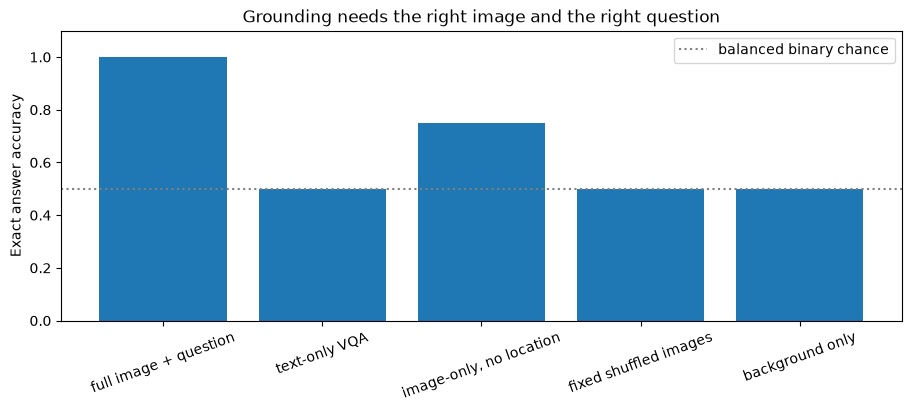

In [21]:
rng = np.random.default_rng(17)
permutation = rng.permutation(len(labels))
background_tokens = projector_tokens.copy()
background_tokens[:, :2] = 0.
modality_logits = {
    'full image + question': projector_logits,
    'text-only VQA': decode_answers(np.zeros_like(projector_tokens), attention, text_states, language, unembed),
    'image-only, no location': decode_answers(projector_tokens, np.full_like(attention, .25), text_states, language, unembed),
    'fixed shuffled images': decode_answers(projector_tokens[permutation], attention, text_states, language, unembed),
    'background only': decode_answers(background_tokens, attention, text_states, language, unembed),
}
modality_scores = [accuracy(logits, labels) for logits in modality_logits.values()]
for name, score in zip(modality_logits, modality_scores):
    print(f'{name:25s} {score:.4f}')
fig, ax = plt.subplots(figsize=(9, 4), constrained_layout=True)
ax.bar(list(modality_logits), modality_scores)
ax.axhline(.5, linestyle=':', color='grey', label='balanced binary chance')
ax.set(ylabel='Exact answer accuracy', ylim=(0, 1.1), title='Grounding needs the right image and the right question')
ax.tick_params(axis='x', rotation=20)
ax.legend()
plt.show()

<details><summary>Expected output and interpretation</summary>

Full image+question scores 1.0; text-only scores 0.5; image-only scores 0.75; background-only scores 0.5. The fixed shuffled-image control scores 0.5 for the frozen seed-17 permutation. Image-only does not collapse to chance because same-color scenes need no location selection. Compare only the mixed-color subset if you want the stricter question-use test, and label that subset analysis explicitly.

</details>

## Try it yourself

The correction was designed for a swapped camera. Keep the adapter fixed and turn the camera swap off. Predict before executing: will the projector adapter preserve the original unshifted-camera task? Will ordinary language color identity change? This tests a changed visual domain, not just a new image seed.

Then change `attention_strength` from 6 to 0. Predict which of the modality controls becomes identical to the full model. Look for a condition in which both adapters preserve high VQA but fail to use the question.

Changed-domain base / projector / language: [1.0, 0.0, 0.0]


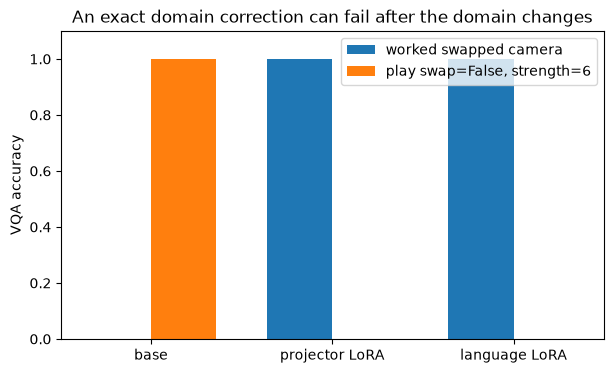

In [22]:
camera_swap = False  # changed domain; True recovers the main calibration task
attention_strength = 6.0  # try 0 after forecasting the question-use effect
play_features = vision_features(patchify(images), camera_swap)
play_attention = query_attention(queries, keys, attention_strength)
play_scores = []
for name in ['base', 'projector LoRA', 'language LoRA']:
    dP, dL = conditions[name]
    tokens = project_tokens(play_features, projector, dP)
    logits = decode_answers(tokens, play_attention, text_states, language + dL, unembed)
    play_scores.append(accuracy(logits, labels))
print('Changed-domain base / projector / language:', play_scores)
fig, ax = plt.subplots(figsize=(7, 4))
x = np.arange(3)
ax.bar(x-.18, [0., 1., 1.], width=.36, label='worked swapped camera')
ax.bar(x+.18, play_scores, width=.36, label=f'play swap={camera_swap}, strength={attention_strength:g}')
ax.set(xticks=x, xticklabels=['base', 'projector LoRA', 'language LoRA'], ylabel='VQA accuracy', ylim=(0, 1.1), title='An exact domain correction can fail after the domain changes')
ax.legend()
plt.show()

<details><summary>Expected output</summary>

For camera swap False and strength 6, base / projector / language VQA is `[1.0,0.0,0.0]`. Both fixed adapters now apply an unnecessary reversal. Projector LoRA still leaves the text-only identity probe unchanged because it never modifies the text pathway.

</details>

## Interpreting the result

Projector and language-module LoRA are not interchangeable even when task accuracy, rank and update norm match. The site determines which representations are changed. Here a known visual calibration error can be corrected before entering language space; the language-site correction leaks into ordinary text states. That side effect follows from the explicit architecture, not a measured law about pretrained models.

A correct answer plus failed text-only and shuffled controls supports use of visual evidence on this task. Target-object patch recovery supports a causal route through that region. Language identity tests expose one preservation cost. You need all three views: any one can look good while another fails.

## Bridge to the mini VLM in 12.3

[Visual Instruction Tuning](https://arxiv.org/abs/2304.08485) connects a visual encoder to a language model and trains for visual instruction following. Section 12.3 uses SigLIP patch embeddings, a patch-merging projector and GPT-2; our RGB means, linear projector and one-step decoder occupy analogous positions, but are not those model components.

To transfer this exercise, retain paired images, question tokens and target answers; cache **the same pretrained visual features** for every site condition; inject LoRA into named projector linear layers versus named language-model projections; freeze and verify all other parameters; and compare visual-token changes, object/background patch effects, text-only/image-only/shuffled controls and a prespecified language-preservation set. Record factor scaling, target-module paths, trainable counts and data roles. The language update here is a single residual value map, not a replication of LoRA across GPT-2 attention/MLP modules.

The default notebook intentionally has no real-model run cell.

## Limitations

The visual encoder is patch-mean color, the question vocabulary has two locations, and the answer vocabulary has two tokens. The weights and exact adapters are constructed, not learned. Background independence and the clean projector/text separation are architectural facts of the fixture. Thirty-two enumerated examples give exact finite-case checks, not broad compositional or natural-image generalization. One random seed does not characterize an adaptation distribution. Patching depends on the selected clean/counterfactual pair and the signed denominator; it does not directly identify every necessary route.

## Summary of 4️⃣

You have implemented an image-to-token pipeline, two adaptation sites, controls and causal measurements. Your strongest supported claim is about this complete finite fixture: identical repaired VQA can hide different language costs, and patch recovery alone cannot establish answer correctness.

# ☆ Bonus

## Further research / anomaly hunting

1. Restrict to mixed-color scenes and compare image-only against question-conditioned accuracy. Why does the former drop from 0.75 to 0.5?
2. Change the background channel to carry a color cue correlated with the answer, then break that correlation. Which background patch control becomes diagnostic? Keep the changed fixture explicit.
3. Interpolate adapter scale from 0 to 1 without training. Predict the exact tie at scale 0.5 and explain why the hard-accuracy curve can look like a transition while the logits change linearly.
4. With the pretrained 12.3 architecture on paper, draw which visual and text representations pass through each candidate LoRA module. Which language-preservation tests would distinguish those sites? This is a design exercise, not permission to run training.

### Further Reading

- [LoRA: Low-Rank Adaptation of Large Language Models](https://arxiv.org/abs/2106.09685): frozen-weight adaptation, factor scaling and low-rank updates.
- [Visual Instruction Tuning](https://arxiv.org/abs/2304.08485): the visual-encoder/projector/language-model architecture and instruction-training connection.
- [LLaVA official implementation](https://github.com/haotian-liu/LLaVA): inspect actual projector and language-module definitions before selecting adapter targets.
- Section 12.3, *Mini VLM from Scratch*: the local pretrained-model bridge.